In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [46]:

df = pd.read_csv( "/Users/poojanair/Downloads/KPMG Certification /UrbanKart_Customer_Analytics_Master.csv")
df.head()


,Customer_ID,Customer_Name,Age,Gender,City_Tier,Income,Customer_Tenure_Months,Acquisition_Channel,Website_Visits_Monthly,App_Sessions_Monthly,...,Payment_Delay_Count,Loyalty_Points,Marketing_Response_Rate,Annual_Revenue,Churn,Purchase_Next_30_Days,Customer_Lifetime_Value,Preferred_Category,Preferred_Channel,Customer_Value_Segment
0,CUST000001,Aryan Maharaj,23,Female,Tier 3,471173.0,54,Offline Store,8.0,12.0,...,0,119,0.017,29211.42,0,1,33024.39,Electronics,Website,Medium Value
1,CUST000002,Udant Dewan,37,Female,Tier 2,150000.0,28,Organic Search,20.0,16.0,...,0,1191,0.330,163225.27,0,0,137497.85,Electronics,Website,High Value
2,CUST000003,Gagan Sami,36,Female,Tier 2,1089061.0,18,Affiliate,9.0,12.0,...,0,973,0.229,92828.35,0,1,64319.68,Electronics,Physical Store,High Value
3,CUST000004,Ayushman Chander,40,Male,Tier 1,661655.0,11,Social Media,9.0,5.0,...,2,52,0.132,8063.92,1,0,2384.79,Grocery,Website,Low Value
4,CUST000005,Viraj Tiwari,58,Male,Tier 1,220959.0,10,Social Media,11.0,9.0,...,0,55,0.258,9955.62,0,0,4263.70,Fashion,Mobile App,Low Value


In [47]:
df.tail()

,Customer_ID,Customer_Name,Age,Gender,City_Tier,Income,Customer_Tenure_Months,Acquisition_Channel,Website_Visits_Monthly,App_Sessions_Monthly,...,Payment_Delay_Count,Loyalty_Points,Marketing_Response_Rate,Annual_Revenue,Churn,Purchase_Next_30_Days,Customer_Lifetime_Value,Preferred_Category,Preferred_Channel,Customer_Value_Segment
19995,CUST019996,Advik Sachdev,46,Female,Tier 1,499169.0,33,Offline Store,15.0,9.0,...,1,425,0.332,62862.55,0,1,64436.02,Home & Kitchen,Mobile App,High Value
19996,CUST019997,Yug Upadhyay,42,Female,Tier 1,945257.0,15,Organic Search,4.0,2.0,...,2,11,0.133,509.19,1,0,170.81,Grocery,Website,Low Value
19997,CUST019998,Priya Golla,24,Male,Tier 1,1680032.0,61,Email,7.0,15.0,...,2,131,0.223,36693.97,0,0,34248.61,Sports & Fitness,Mobile App,Medium Value
19998,CUST019999,Charita Ray,32,Male,Tier 2,312155.0,44,Referral,10.0,18.0,...,0,1460,0.024,76552.31,1,0,89562.24,Electronics,Physical Store,High Value
19999,CUST020000,Wazir Borah,25,Male,Tier 1,572246.0,17,Marketplace,4.0,3.0,...,0,61,0.000,497.18,1,0,176.98,Fashion,Physical Store,Low Value


In [48]:
df.columns

Index(['Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City_Tier', 'Income',
       'Customer_Tenure_Months', 'Acquisition_Channel',
       'Website_Visits_Monthly', 'App_Sessions_Monthly',
       'Purchase_Frequency_Monthly', 'Average_Order_Value',
       'Discount_Usage_Rate', 'Orders_Last_12M', 'Days_Since_Last_Purchase',
       'Return_Rate', 'Support_Tickets_12M', 'Customer_Satisfaction_Score',
       'Payment_Delay_Count', 'Loyalty_Points', 'Marketing_Response_Rate',
       'Annual_Revenue', 'Churn', 'Purchase_Next_30_Days',
       'Customer_Lifetime_Value', 'Preferred_Category', 'Preferred_Channel',
       'Customer_Value_Segment'],
      dtype='object')

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 28 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer_ID                  20000 non-null  object 
 1   Customer_Name                20000 non-null  object 
 2   Age                          20000 non-null  int64  
 3   Gender                       20000 non-null  object 
 4   City_Tier                    20000 non-null  object 
 5   Income                       19400 non-null  float64
 6   Customer_Tenure_Months       20000 non-null  int64  
 7   Acquisition_Channel          19600 non-null  object 
 8   Website_Visits_Monthly       19300 non-null  float64
 9   App_Sessions_Monthly         19400 non-null  float64
 10  Purchase_Frequency_Monthly   20000 non-null  float64
 11  Average_Order_Value          20000 non-null  float64
 12  Discount_Usage_Rate          20000 non-null  float64
 13  Orders_Last_12M 

In [50]:
df.describe()

,Age,Income,Customer_Tenure_Months,Website_Visits_Monthly,App_Sessions_Monthly,Purchase_Frequency_Monthly,Average_Order_Value,Discount_Usage_Rate,Orders_Last_12M,Days_Since_Last_Purchase,Return_Rate,Support_Tickets_12M,Customer_Satisfaction_Score,Payment_Delay_Count,Loyalty_Points,Marketing_Response_Rate,Annual_Revenue,Churn,Purchase_Next_30_Days,Customer_Lifetime_Value
count,20000.000000,1.940000e+04,20000.000000,19300.000000,19400.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,19200.000000,20000.000000,20000.000000,19400.00000,20000.000000,20000.000000,20000.000000,20000.000000
mean,38.193900,5.921987e+05,24.061250,12.323990,13.882990,0.537693,1845.453167,0.406639,6.611900,72.452850,0.132860,0.969450,3.505293,0.813400,230.278750,0.25482,44288.260337,0.247000,0.451750,32197.683549
std,11.477238,4.353917e+05,15.600688,9.169258,10.394052,0.386064,1350.782124,0.200085,5.540155,69.246223,0.097917,1.554296,0.823314,0.975155,397.115611,0.21910,46386.761759,0.431278,0.497679,38963.674642
min,18.000000,1.500000e+05,1.000000,0.000000,0.000000,0.100000,170.560000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.00000,491.190000,0.000000,0.000000,64.760000
25%,30.000000,2.991995e+05,12.000000,6.000000,7.000000,0.280000,962.485000,0.254000,3.000000,26.000000,0.059000,0.000000,3.000000,0.000000,43.000000,0.05500,4851.805000,0.000000,0.000000,2543.910000
50%,38.000000,4.707170e+05,21.000000,10.000000,11.000000,0.440000,1464.940000,0.394000,5.000000,50.000000,0.118000,0.000000,3.610000,1.000000,106.000000,0.22400,32966.325000,0.000000,0.000000,20346.305000
75%,46.000000,7.437775e+05,32.000000,16.000000,18.000000,0.680000,2291.930000,0.550000,9.000000,94.000000,0.190000,2.000000,4.110000,1.000000,254.000000,0.40000,67364.075000,0.000000,1.000000,46801.957500
max,70.000000,5.000000e+06,72.000000,167.000000,135.000000,5.050000,27993.310000,1.000000,75.000000,365.000000,0.663000,21.000000,5.000000,8.000000,9649.000000,1.00000,513835.370000,1.000000,1.000000,466257.010000


In [51]:
df.isnull().sum()

Customer_ID                      0
Customer_Name                    0
Age                              0
Gender                           0
City_Tier                        0
Income                         600
Customer_Tenure_Months           0
Acquisition_Channel            400
Website_Visits_Monthly         700
App_Sessions_Monthly           600
Purchase_Frequency_Monthly       0
Average_Order_Value              0
Discount_Usage_Rate              0
Orders_Last_12M                  0
Days_Since_Last_Purchase         0
Return_Rate                      0
Support_Tickets_12M              0
Customer_Satisfaction_Score    800
Payment_Delay_Count              0
Loyalty_Points                   0
Marketing_Response_Rate        600
Annual_Revenue                   0
Churn                            0
Purchase_Next_30_Days            0
Customer_Lifetime_Value          0
Preferred_Category             500
Preferred_Channel                0
Customer_Value_Segment           0
dtype: int64

In [52]:
df['Income'].head() # replace by median

0     471173.0
1     150000.0
2    1089061.0
3     661655.0
4     220959.0
Name: Income, dtype: float64

In [53]:
df['Website_Visits_Monthly'].head() # replace by mode

0     8.0
1    20.0
2     9.0
3     9.0
4    11.0
Name: Website_Visits_Monthly, dtype: float64

In [54]:
df['App_Sessions_Monthly'].head() # replace by mode

0    12.0
1    16.0
2    12.0
3     5.0
4     9.0
Name: App_Sessions_Monthly, dtype: float64

In [55]:
df['Customer_Satisfaction_Score'].head() # replace by median

0    4.29
1    3.46
2    4.14
3    1.43
4    3.91
Name: Customer_Satisfaction_Score, dtype: float64

In [56]:
df['Marketing_Response_Rate'].head() # replace by median

0    0.017
1    0.330
2    0.229
3    0.132
4    0.258
Name: Marketing_Response_Rate, dtype: float64

In [57]:
df['Preferred_Category'].head() # replace by Mode

0    Electronics
1    Electronics
2    Electronics
3        Grocery
4        Fashion
Name: Preferred_Category, dtype: object

In [58]:
df['Acquisition_Channel'].head() # replace by Mode

0     Offline Store
1    Organic Search
2         Affiliate
3      Social Media
4      Social Media
Name: Acquisition_Channel, dtype: object

In [59]:
df['Income'] = df['Income'].fillna(df['Income'].median())

In [60]:
df['Preferred_Category'].isnull().sum()

np.int64(500)

In [61]:
for i in ["Customer_Satisfaction_Score","Marketing_Response_Rate"] :
  df[i] = df[i].fillna(df[i].median())

In [62]:
for i in ["Website_Visits_Monthly","App_Sessions_Monthly","Preferred_Category","Acquisition_Channel"] :
  df[i] = df[i].fillna(df[i].mode()[0])

In [63]:
df['Preferred_Category'].mode()[0]

'Fashion'

In [64]:
df["Income"].isnull().sum()

np.int64(0)

In [65]:
df['Income'].shape

(20000,)

In [66]:
X = df[["Income"]] # feature
y = df['Annual_Revenue'] # target

In [67]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state=11)

In [68]:
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(15000, 1) (5000, 1) (15000,) (5000,)


In [69]:
X_test.head()

,Income
2440,433335.0
7382,512454.0
13064,432392.0
18810,593137.0
359,298622.0


In [70]:
from sklearn.linear_model import LinearRegression
model_1 = LinearRegression() #

In [71]:
model_1.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [72]:
y_pred = model_1.predict(X_test)

In [73]:
print(y_test.values)
print(y_pred)

[ 39316.23  80480.01  46388.43 ...  61515.83  70520.72 103976.81]
[39191.15383353 41647.11749015 39161.8818037  ... 56780.22920913
 33999.9781848  53916.75419766]


In [74]:
from sklearn.metrics import r2_score
print(r2_score(y_test,y_pred))

0.08919279868626795


In [75]:
df.columns

Index(['Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City_Tier', 'Income',
       'Customer_Tenure_Months', 'Acquisition_Channel',
       'Website_Visits_Monthly', 'App_Sessions_Monthly',
       'Purchase_Frequency_Monthly', 'Average_Order_Value',
       'Discount_Usage_Rate', 'Orders_Last_12M', 'Days_Since_Last_Purchase',
       'Return_Rate', 'Support_Tickets_12M', 'Customer_Satisfaction_Score',
       'Payment_Delay_Count', 'Loyalty_Points', 'Marketing_Response_Rate',
       'Annual_Revenue', 'Churn', 'Purchase_Next_30_Days',
       'Customer_Lifetime_Value', 'Preferred_Category', 'Preferred_Channel',
       'Customer_Value_Segment'],
      dtype='object')

In [76]:
df[['Age', 'Income',
       'Customer_Tenure_Months', 'Acquisition_Channel',
       'Website_Visits_Monthly', 'App_Sessions_Monthly',
       'Purchase_Frequency_Monthly', 'Average_Order_Value',
       'Discount_Usage_Rate', 'Orders_Last_12M', 'Days_Since_Last_Purchase',
       'Return_Rate', 'Support_Tickets_12M', 'Customer_Satisfaction_Score',
       'Payment_Delay_Count', 'Loyalty_Points', 'Marketing_Response_Rate']]

,Age,Income,Customer_Tenure_Months,Acquisition_Channel,Website_Visits_Monthly,App_Sessions_Monthly,Purchase_Frequency_Monthly,Average_Order_Value,Discount_Usage_Rate,Orders_Last_12M,Days_Since_Last_Purchase,Return_Rate,Support_Tickets_12M,Customer_Satisfaction_Score,Payment_Delay_Count,Loyalty_Points,Marketing_Response_Rate
0,23,471173.0,54,Offline Store,8.0,12.0,0.29,2315.36,0.356,6,53,0.087,0,4.29,0,119,0.017
1,37,150000.0,28,Organic Search,20.0,16.0,1.60,2752.12,0.314,23,13,0.251,2,3.46,0,1191,0.330
2,36,1089061.0,18,Affiliate,9.0,12.0,0.94,3731.57,0.212,15,50,0.099,0,4.14,0,973,0.229
3,40,661655.0,11,Social Media,9.0,5.0,0.54,1372.18,0.291,4,4,0.215,5,1.43,2,52,0.132
4,58,220959.0,10,Social Media,11.0,9.0,0.24,1153.17,0.308,4,73,0.290,0,3.91,0,55,0.258
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,46,499169.0,33,Offline Store,15.0,9.0,0.58,2875.13,0.183,9,97,0.103,0,3.62,1,425,0.332
19996,42,945257.0,15,Organic Search,4.0,2.0,0.12,1109.90,0.313,1,248,0.127,0,3.01,2,11,0.133
19997,24,1680032.0,61,Email,7.0,15.0,0.27,1926.50,0.425,3,103,0.054,1,3.29,2,131,0.223
19998,32,312155.0,44,Referral,10.0,18.0,0.50,4236.33,0.317,12,120,0.195,1,4.16,0,1460,0.024


In [77]:
X = df[['Age', 'Income',
       'Customer_Tenure_Months',
       'Website_Visits_Monthly', 'App_Sessions_Monthly',
       'Purchase_Frequency_Monthly', 'Average_Order_Value',
       'Discount_Usage_Rate', 'Orders_Last_12M', 'Days_Since_Last_Purchase',
       'Return_Rate', 'Support_Tickets_12M', 'Customer_Satisfaction_Score',
       'Payment_Delay_Count', 'Loyalty_Points', 'Marketing_Response_Rate']] # feature
y = df['Annual_Revenue'] # target
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state=11)
model_1 = LinearRegression()
model_1.fit(X_train,y_train)
y_pred = model_1.predict(X_test)
print(r2_score(y_test,y_pred))

0.801834179126056


In [78]:
print(y_test.values)
print(y_pred)

[ 39316.23  80480.01  46388.43 ...  61515.83  70520.72 103976.81]
[ 39404.72332126  85116.50831815  62454.15534911 ...  57469.73745051
  83152.88146475 105126.23327204]


In [79]:
X = df[["Income","Age","Customer_Tenure_Months","Website_Visits_Monthly",
        "Purchase_Frequency_Monthly","Average_Order_Value"]] # feature
y = df['Annual_Revenue'] # target
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state=11)
model_1 = LinearRegression()
model_1.fit(X_train,y_train)
y_pred = model_1.predict(X_test)
print(r2_score(y_test,y_pred))

0.7701284674610782


Note: you may need to restart the kernel to use updated packages.
Feature shape: (20000, 21)
Target shape: (20000,)
Missing target values: 0
Numerical columns: 16
Categorical columns: 5

Numerical features:
['Age', 'Income', 'Customer_Tenure_Months', 'Website_Visits_Monthly', 'App_Sessions_Monthly', 'Purchase_Frequency_Monthly', 'Average_Order_Value', 'Discount_Usage_Rate', 'Orders_Last_12M', 'Days_Since_Last_Purchase', 'Return_Rate', 'Support_Tickets_12M', 'Customer_Satisfaction_Score', 'Payment_Delay_Count', 'Loyalty_Points', 'Marketing_Response_Rate']

Categorical features:
['Gender', 'City_Tier', 'Acquisition_Channel', 'Preferred_Category', 'Preferred_Channel']
Training features: (16000, 21)
Testing features: (4000, 21)
Training target: (16000,)
Testing target: (4000,)


,Model,MAE,RMSE,R2 Score
0,HistGradientBoosting,11911.465,17697.793,0.782
1,Gradient Boosting,12216.599,17895.415,0.778
2,Extra Trees,12434.578,18196.366,0.770
3,Random Forest,12510.485,18412.451,0.764
4,Ridge Regression,14029.517,19681.611,0.731
5,Lasso Regression,14029.990,19682.000,0.731
6,Linear Regression,14030.490,19682.596,0.731
7,Decision Tree,18077.790,28482.266,0.436


Best model: HistGradientBoosting
Best RMSE: 17697.793405266082
Best MAE: 11911.465164497022
Best R2 Score: 0.7824070672301195


,Actual_CLV,Predicted_CLV,Error
10650,345.13,3956.28,-3611.15
2041,43944.58,36147.21,7797.37
8668,10240.37,13910.71,-3670.34
1114,6260.03,2598.74,3661.29
13902,4415.44,11854.68,-7439.24
11963,269.64,877.24,-607.60
11072,54501.04,68289.24,-13788.20
3002,19620.42,9130.66,10489.76
19771,14206.31,26610.53,-12404.22
8115,325.25,6998.17,-6672.92


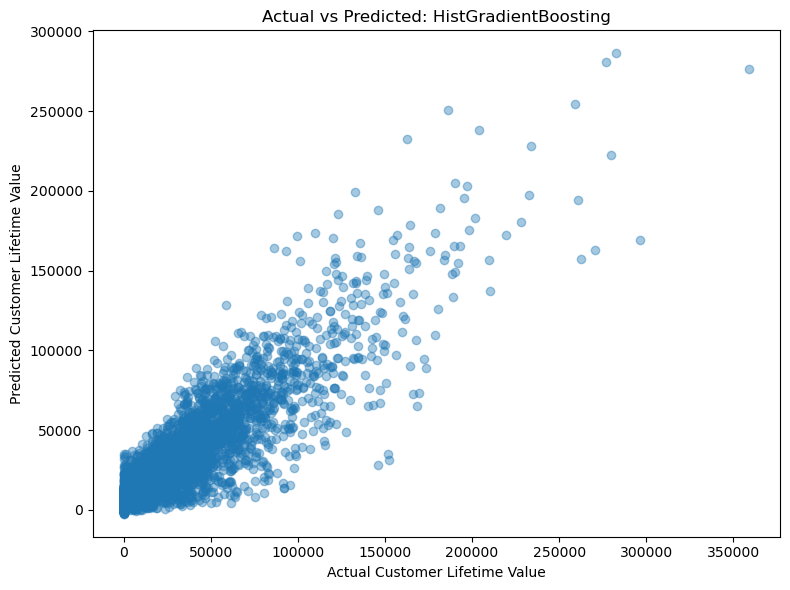

In [80]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

%pip install scikit-learn

# Define target variable
target = "Customer_Lifetime_Value"

# Remove rows where target is missing
df_model = df.dropna(subset=[target]).copy()

# Remove columns that should not be predictors
drop_cols = [
    "Customer_ID",
    "Customer_Name",
    "Customer_Value_Segment",
    "Churn",
    "Purchase_Next_30_Days",
    "Annual_Revenue"
]

# Create feature matrix and target variable
X = df_model.drop(columns=[target] + drop_cols)
y = df_model[target]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Missing target values:", y.isnull().sum())

# Numerical columns
num_cols = X.select_dtypes(include=np.number).columns.tolist()

# Categorical columns
cat_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))

print("\nNumerical features:")
print(num_cols)

print("\nCategorical features:")
print(cat_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Numerical preprocessing
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    # Combine preprocessing and model
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict test-set values
    y_pred = pipeline.predict(X_test)

    # Calculate metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Save results
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

# Display model comparison
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df.round(3))

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model:", best_model_name)
print("Best RMSE:", results_df.iloc[0]["RMSE"])
print("Best MAE:", results_df.iloc[0]["MAE"])
print("Best R2 Score:", results_df.iloc[0]["R2 Score"])

best_predictions = pd.DataFrame({
    "Actual_CLV": y_test,
    "Predicted_CLV": best_model.predict(X_test)
})

best_predictions["Error"] = (
    best_predictions["Actual_CLV"]
    - best_predictions["Predicted_CLV"]
)

display(best_predictions.head(10).round(2))

import matplotlib.pyplot as plt

y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.4)

plt.xlabel("Actual Customer Lifetime Value")
plt.ylabel("Predicted Customer Lifetime Value")
plt.title(f"Actual vs Predicted: {best_model_name}")

plt.tight_layout()
plt.show()

In [81]:
import joblib
import os

model_path = os.path.join(
    os.getcwd(),
    "urbanskart_best_model.pkl"
)

joblib.dump(best_model, model_path)

print("Model saved to:", model_path)
print("File exists:", os.path.exists(model_path))
print("Selected model:", best_model_name)

Model saved to: /Users/poojanair/Downloads/VS Code/urbanskart_best_model.pkl
File exists: True
Selected model: HistGradientBoosting


In [82]:
   import sklearn
   print(sklearn.__version__)

1.7.2
